In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
import numpy as np
import jax
import jax.numpy as jnp
import torch
from model_utils import generate_images_from_latents
from diffusers import (
    UNet2DConditionModel,
    AutoencoderKL,
    LMSDiscreteScheduler
)
from transformers import (
    CLIPTextModel,
    CLIPTokenizerFast,
    CLIPModel
)
from matplotlib import pyplot as plt
from PIL import Image
from functools import partial


/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Hyperparams

In [2]:
repertoire_path = "/workspace/src/output/A cat on a sofa/map_elites/2025-07-29_054359_5642/repertoire/final_repertoire.npz"
random_seed = 14643
random_key = jax.random.PRNGKey(random_seed)
model_name = "stabilityai/sd-turbo"
batch_size = 4

num_inference_steps = 50
guidance_scale = 7.5
prompt = "A cat on a sofa"
learning_rate = 1e-3

TEST_INDEX = 5

# Load the Models

In [3]:
vae = AutoencoderKL.from_pretrained(model_name, subfolder="vae", torch_dtype=torch.float32).cuda()
tokenizer = CLIPTokenizerFast.from_pretrained(model_name, subfolder="tokenizer", torch_dtype=torch.float32)
text_encoder = CLIPTextModel.from_pretrained(model_name, subfolder="text_encoder", torch_dtype=torch.float32).cuda().eval()
unet = UNet2DConditionModel.from_pretrained(model_name, subfolder="unet", torch_dtype=torch.float32).cuda()
unet.enable_gradient_checkpointing()
scheduler = LMSDiscreteScheduler.from_pretrained(model_name, subfolder="scheduler", torch_dtype=torch.float32)
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda") # type: ignore


# Read in the repertoire

In [4]:
repertoire_data = np.load(repertoire_path, allow_pickle=True)

genotypes = repertoire_data['genotypes']
descriptors = repertoire_data['descriptors']
fitnesses = repertoire_data['fitnesses']
centroids = repertoire_data['centroids']

# Visualise some of the images

In [5]:
key, subkey = jax.random.split(random_key)

# Initialize a latent vector for testing
init_latent = jax.random.normal(subkey, shape=(1, 4, 64, 64), dtype=jnp.float32)

# Filter valid genotypes
valid_indices = jnp.where(fitnesses != -jnp.inf)[0]
valid_genotypes = genotypes[valid_indices]

In [ ]:
image = generate_images_from_latents(
    init_latent,
    valid_genotypes[5],
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

In [6]:
# Assuming `image` is your tensor on CPU
def show_image(image):
    image_array = np.array(image.cpu())
    image_array = (image_array - image_array.min()) / (image_array.max() - image_array.min() + 1e-8)
    image_array = (image_array * 255).astype(np.uint8)
    image_array = np.transpose(image_array, (1, 2, 0))
    image_plot = Image.fromarray(image_array, mode="RGB")

    # Show with corrected aspect ratio
    plt.figure(figsize=(10, 2))  # Adjust figsize to better match the image shape
    plt.imshow(image_plot)
    plt.axis('off')  # Optional: hides axis for better viewing
    plt.tight_layout()
    plt.show()
    

In [ ]:
show_image(image)

In [ ]:
# Interesting indices:

bad_images_indices = [0, 1, 2, 6, 7, 9]
good_images_indices = [3, 4, 8]

interesting_to_gradients = [5]


# Gradient updates

In [7]:
from model_utils import fitness_function

def loss_function(
    genotypes,
    prompt,
    generate_images_from_latents_fn,
    tokenizer,
    clip_model,
):
    generated_images = generate_images_from_latents_fn(prompt_embedding=genotypes)
    fitnesses = fitness_function(
        generated_images,
        prompt,
        clip_model=clip_model,
        clip_tokenizer=tokenizer,
        with_grad=True,
    )

    return -fitnesses.mean().squeeze()

generate_images_from_latents_with_grad_fn = partial(generate_images_from_latents,
    latents=init_latent,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
    with_grad=True  # Enable gradients for image generation
)

loss_fn = partial(loss_function,
    prompt=prompt,
    generate_images_from_latents_fn=generate_images_from_latents_with_grad_fn,
    tokenizer=tokenizer,
    clip_model=clip_model,
)



In [8]:
images = []
torch_genotype = torch.nn.Parameter(
            torch.tensor(valid_genotypes[TEST_INDEX], dtype=torch.float32, device='cuda', requires_grad=True)
        )
adam_optimiser = torch.optim.Adam([torch_genotype], lr=learning_rate)

for i in range(10):
    loss = loss_fn(torch_genotype)
    loss.backward()
    adam_optimiser.step()

    print("Iteration:", i, "Loss:", loss.item())
    torch.cuda.empty_cache()
    
    genotypes_jnp = jnp.array(torch_genotype.detach().cpu().numpy(), dtype=jnp.float32)
    
    new_image = generate_images_from_latents(
        init_latent,
        genotypes_jnp,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        scheduler=scheduler,
        unet=unet,
        vae=vae,
    ).squeeze()
    
    images.append((new_image).cpu().detach().numpy())



Iteration: 0 Loss: -0.2610315680503845
Iteration: 1 Loss: -0.23459617793560028
Iteration: 2 Loss: -0.24133223295211792
Iteration: 3 Loss: -0.23776692152023315
Iteration: 4 Loss: -0.2548828423023224
Iteration: 5 Loss: -0.24971312284469604
Iteration: 6 Loss: -0.26109594106674194
Iteration: 7 Loss: -0.2787626385688782
Iteration: 8 Loss: -0.2902103662490845
Iteration: 9 Loss: -0.28118211030960083


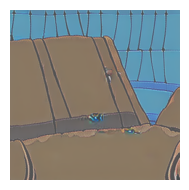

In [9]:

test_image = generate_images_from_latents(
    init_latent,
    valid_genotypes[TEST_INDEX],
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    scheduler=scheduler,
    unet=unet,
    vae=vae,
).squeeze()

show_image(test_image)



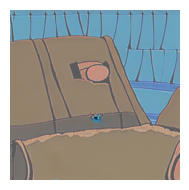

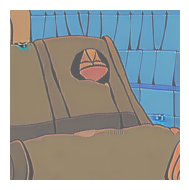

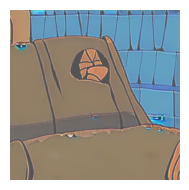

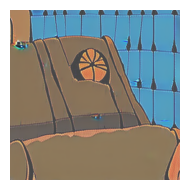

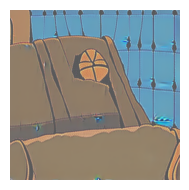

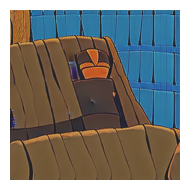

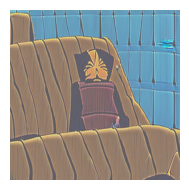

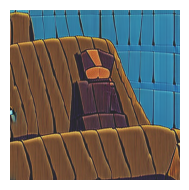

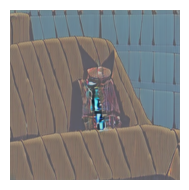

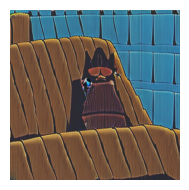

In [10]:
# Assuming `image` is your tensor on CPU
def show_image(image):
    image_array = np.array(image)
    image_array = (image_array - image_array.min()) / (image_array.max() - image_array.min() + 1e-8)
    image_array = (image_array * 255).astype(np.uint8)
    image_array = np.transpose(image_array, (1, 2, 0))
    image_plot = Image.fromarray(image_array, mode="RGB")

    # Show with corrected aspect ratio
    plt.figure(figsize=(10, 2))  # Adjust figsize to better match the image shape
    plt.imshow(image_plot)
    plt.axis('off')  # Optional: hides axis for better viewing
    plt.tight_layout()
    plt.show()

for image in images:
    show_image(image)